# Eksperimen Encoder dan Scaler pada data Pencapaian Kecepatan

**Tujuan**: memprediksi pencapaian_kecepatan (data kecepatan koridor Jakarta tahun 2023, gabungan 12 bulan) dengan regresi linear, lalu membandingkan MAE (rata-rata dan standar deviasi dari cross validation) pada berbagai teknik transformasi data. 

## 1. Persiapan dan pemuatan data

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (MinMaxScaler, StandardScaler, RobustScaler, OneHotEncoder, OrdinalEncoder,)

pd.set_option("display.max_columns", None)

Semua file CSV bulanan dibaca lalu digabung menjadi satu dataframe. Nama bulan diambil dari nama file dan disimpan sebagai kolom `bulan`. 

In [3]:
DATA_DIR = Path('data')
files = sorted(DATA_DIR.glob('*.csv')) or sorted(Path('.').glob('*.csv'))

if not files:
    raise FileNotFoundError(f"File CSV tidak ditemukan. Folder kerja saat ini: {Path.cwd()}")

print('Jumlah file CSV ditemukan:', len(files))

bulan = ['januari', 'februari', 'maret', 'april', 'mei', 'juni', 'juli', 'agustus', 'september', 'oktober', 'november', 'desember',]

bagian_data = []
for file in files:
    bagian = pd.read_csv(file)
    bagian.columns = bagian.columns.str.strip().str.lower()
    nama_file = file.name.lower()
    bagian['bulan'] = next((b for b in bulan if b in nama_file), 'tidak diketahui')
    bagian_data.append(bagian)

data = pd.concat(bagian_data, ignore_index=True)

print('Ukuran data sebelum dibersihkan:', data.shape)
display(data.head())

Jumlah file CSV ditemukan: 12
Ukuran data sebelum dibersihkan: (986, 10)


,waktu,arah,koridor,target_kecepatan,jarak,target_waktu_tempuh,pencapaian_kecepatan_per_koridor,pencapaian_kecepatan,pencapaian_waktu_tempuh,bulan
0,pagi,Selatan - Pusat,Lenteng Agung - Ps. Minggu - Supomo - dr. Saha...,21.0,19.62,56.06,22.77,24.36,58.82,agustus
1,pagi,Selatan - Pusat,Cilandak KKO - Warung Buncit - Mampang Prapata...,21.0,13.36,38.17,24.14,24.36,36.88,agustus
2,pagi,Selatan - Pusat,Pangeran Antasari - Prapanca - Iskandarsyah - ...,21.0,11.13,31.80,29.64,24.36,25.99,agustus
3,pagi,Selatan - Pusat,Pondok Labu - Fatmawati - Panglima Polim - Sis...,21.0,16.25,46.43,25.82,24.36,44.35,agustus
4,pagi,Selatan - Pusat,Pasar Jumat - Metro Pondok Indah - Iskandar Mu...,21.0,15.87,45.34,28.18,24.36,37.33,agustus


## Pemeriksaan nilai kosong dan pemisahan fitur
Baris yang nilai target-nya kosong tidak bisa dipakai untuk melatih maupun mengevaluasi model, jadi dibuang. Nilai kosong pad afitur lain tidak diisi di sini, tetapi di dalam pipline `SimpleImputer` supaya statistik pengisian dihitung hanya dari data latih pada setiap fold dan tidak bocor ke data uji. 

In [4]:
target = 'pencapaian_kecepatan'

print('Missing value setiap kolom:')
print(data.isnull().sum())

data = data.dropna(subset=[target]).reset_index(drop=True)

print('\nData yang targetnya kosong akan dihapus')
print('Ukuran data setelah dibersihkan:', data.shape)

numeric_features = data.select_dtypes(include='number').columns.drop(target).tolist()
categorical_features = [col for col in data.columns if col not in numeric_features + [target]]

X_numeric = data[numeric_features]
X_categorical = data[categorical_features]
X_all = data[numeric_features + categorical_features]
y = data[target]

print('\nFitur numerik:', numeric_features)
print('Fitur kategorikal:', categorical_features)
print('Target', target)

Missing value setiap kolom:
waktu                                2
arah                                 2
koridor                              2
target_kecepatan                    43
jarak                                2
target_waktu_tempuh                  2
pencapaian_kecepatan_per_koridor     2
pencapaian_kecepatan                 2
pencapaian_waktu_tempuh              2
bulan                                0
dtype: int64

Data yang targetnya kosong akan dihapus
Ukuran data setelah dibersihkan: (984, 10)

Fitur numerik: ['target_kecepatan', 'jarak', 'target_waktu_tempuh', 'pencapaian_kecepatan_per_koridor', 'pencapaian_waktu_tempuh']
Fitur kategorikal: ['waktu', 'arah', 'koridor', 'bulan']
Target pencapaian_kecepatan


## 2. Pengaturan Evaluasi
Evaluasi model menggunakan `5-fold` cross validation dengan metrik Mean Absolute Error (MAE). Setiap skenario menggunakan pembagian data yang sama agar hasilnya bisa dibandingkan. 

In [7]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
hasil = {}

def evaluasi_mae(nama, model, X):
    skor = cross_val_score(model, X, y, cv=cv, scoring='neg_mean_absolute_error')
    mae = -skor
    hasil[nama] = {
        'Skenario': nama,
        'MAE rata-rata': mae.mean(),
        'Standar deviasi MAE': mae.std()
    }
    print(f'{nama} MAE: {mae.mean():.3f} ({mae.std():.3f})')

def buat_pipeline(imputer, *langkah):
    return Pipeline([('imputer', imputer), *langkah, ('regresi', LinearRegression())])

## 3. Skenario 1: Data asli
Pada skenario ini, model menggunakan fitur numerik tanpa scaling maupun encoding. Missing value diisi menggunakan median. 

In [8]:
model_asli = buat_pipeline(SimpleImputer(strategy='median'))
evaluasi_mae('1. Original data', model_asli, X_numeric)

1. Original data MAE: 2.017 (0.128)


## 4. Skenario 2: Scaling Fitur Numerik
Pada skenario ini, dilakukan perbandingan tiga metode scaling, yaitu `MinMaxScaler`, `StandardScaler`, dan `RobustScaler`.

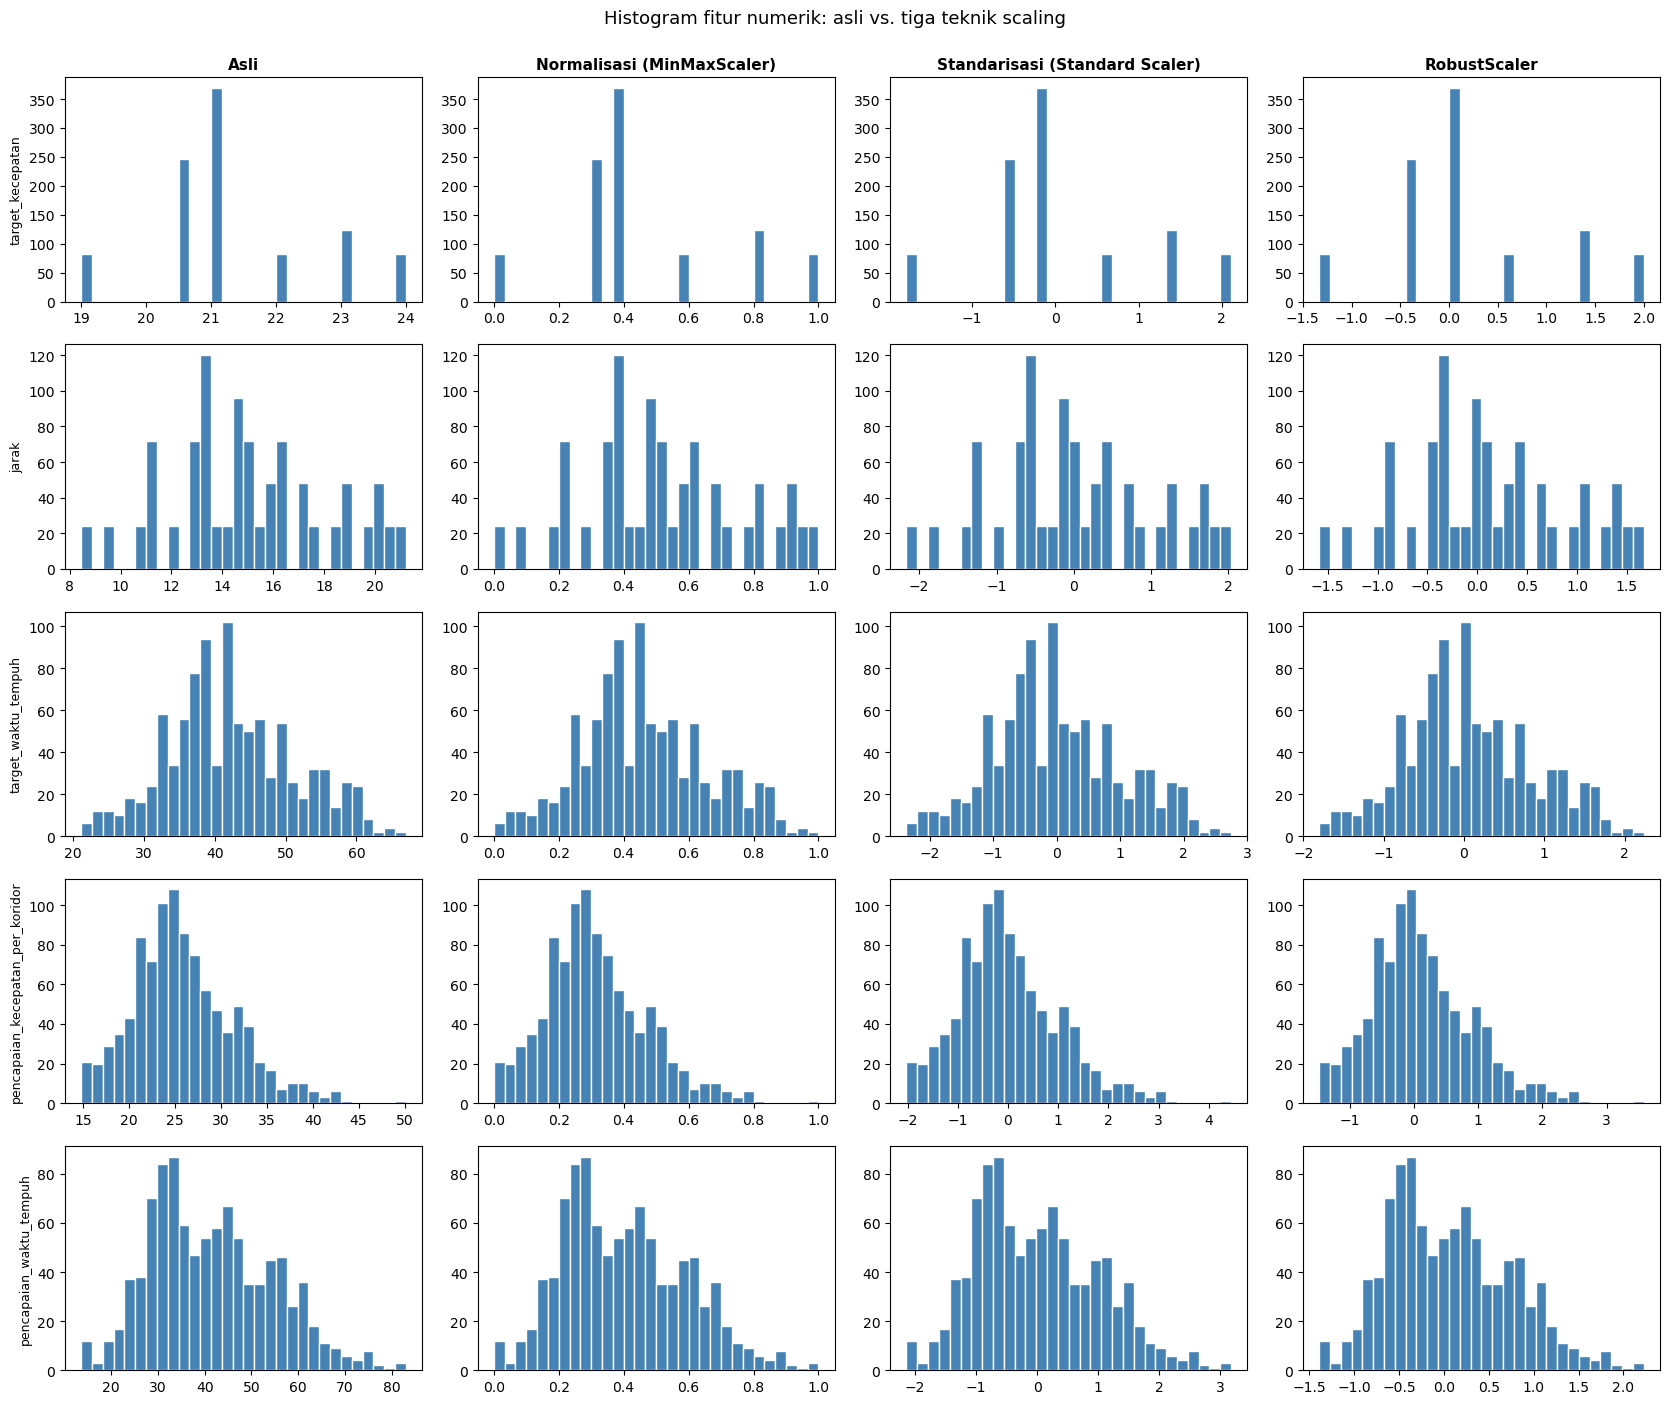

In [11]:
X_num_imp = pd.DataFrame(
    SimpleImputer(strategy='median').fit_transform(X_numeric), 
    columns=numeric_features
)

scalers = {
    'Asli': None, 
    'Normalisasi (MinMaxScaler)': MinMaxScaler(),
    'Standarisasi (Standard Scaler)': StandardScaler(),
    'RobustScaler': RobustScaler(),
}

fig, axes = plt.subplots(len(numeric_features), len(scalers), figsize=(4.2 * len(scalers), 2.8 * len(numeric_features)),)

for j, (judul, scaler) in enumerate(scalers.items()):
    nilai = X_num_imp.values if scaler is None else scaler.fit_transform(X_num_imp)
    for i, fitur in enumerate(numeric_features):
        ax = axes[i, j]
        ax.hist(nilai[:, i], bins=30, color='steelblue', edgecolor='white')
        if i == 0:
            ax.set_title(judul, fontsize=11, fontweight='bold')
        if j == 0:
            ax.set_ylabel(fitur, fontsize=9)

fig.suptitle('Histogram fitur numerik: asli vs. tiga teknik scaling', y=1.0, fontsize=13)
plt.tight_layout()
plt.show()

Bentuk distribusi sama pada ketiganya. Perubahan terjadi hanya pada skala sumbu-x, yaitu MinMax memetakan ke [0,1], StandardScaler ke rata-rata 0 dan standar deviasi 1, sedangkan RobustScaler memakai median dan IQR sehingga lebih tahan terhadap outlier. 

In [12]:
evaluasi_mae('2. MinMaxScaler', buat_pipeline(SimpleImputer(strategy='median'), ('scaler', MinMaxScaler())), X_numeric)
evaluasi_mae('3. StandardScaler', buat_pipeline(SimpleImputer(strategy='median'), ('scaler', StandardScaler())), X_numeric)
evaluasi_mae('4. RobustScaler', buat_pipeline(SimpleImputer(strategy='median'), ('scaler', RobustScaler())), X_numeric)

2. MinMaxScaler MAE: 2.017 (0.128)
3. StandardScaler MAE: 2.017 (0.128)
4. RobustScaler MAE: 2.017 (0.128)


## 5. Skenario 3: Encoding Fitur Kategorikal
Pada skenario ini, fitur kategorikal diubah menjadi bentuk numerik menggunakan `OrdinalEncoder` dan `OneHotEncoder`. Evaluasi dilakukan hanya menggunakan fitur kategorikal. 
Missing value diisi dengan modus. Untuk kategori yang tidak ditemukan saat training, OrdinalEncoder memberikan nilai -1, sedangkan OneHotEncoder mengabaikannya.

In [15]:
def ordinal():
    return OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

def onehot():
    return OneHotEncoder(handle_unknown='ignore', sparse_output=False)

imp_kat = lambda: SimpleImputer(strategy='most_frequent')

evaluasi_mae('5. OrdinalEncoder', buat_pipeline(imp_kat(), ('encoder', ordinal())), X_categorical)
evaluasi_mae('6. OneHotEncoder', buat_pipeline(imp_kat(), ('encoder', onehot())), X_categorical)

5. OrdinalEncoder MAE: 3.324 (0.134)
6. OneHotEncoder MAE: 2.954 (0.162)


## 6. Skenario 4: Kombinasi Encoder dan Scaler
Pada skenario ini, fitur numerik dan kategorikal digunakan secara bersamaan. Missing value pada fitur numerik diisi dengan median, sedangkan fitur kategorikal diisi dengan modus sebelum dilakukan encoding. 
Pengujian dilakukan dengan menggabungkan dua encoder (OrdinalEncoder dan OneHotEncoder) serta tiga scaler (MinMaxScaler, StandardScaler, dan RobustScaler), sehingga diperoleh 6 kombinasi. Keenam kombinasi diuji untuk melihat perbedaan hasil MAE. 

In [16]:
def buat_model_gabungan(encoder, scaler):
    preprocess = ColumnTransformer(
        transformers=[
            ('num', SimpleImputer(strategy='median'), numeric_features),
            ('kat', Pipeline([('imputer', imp_kat()), ('encoder', encoder)]), categorical_features),
        ],
        sparse_threshold=0,
    )
    return Pipeline([
        ('preprocess', preprocess),
        ('scaler', scaler),
        ('regresi', LinearRegression()),
    ])

kombinasi = [
    ('7. OneHotEncoder + MinMaxScaler', onehot, MinMaxScaler),
    ('8. OrdinalEncoder + MinMaxScaler', ordinal, MinMaxScaler),
    ('9. OneHotEncoder + StandardScaler', onehot, StandardScaler),
    ('10. OrdinalEncoder + StandardScaler', ordinal, StandardScaler), 
    ('11. OneHotEncoder + RobustScaler', onehot, RobustScaler),
    ('12. OrdinalEncoder + RobustScaler', ordinal, RobustScaler),
]

for nama, enc, sc, in kombinasi:
    evaluasi_mae(nama, buat_model_gabungan(enc(), sc()), X_all)

7. OneHotEncoder + MinMaxScaler MAE: 1.331 (0.070)
8. OrdinalEncoder + MinMaxScaler MAE: 1.928 (0.151)
9. OneHotEncoder + StandardScaler MAE: 1.331 (0.070)
10. OrdinalEncoder + StandardScaler MAE: 1.928 (0.151)
11. OneHotEncoder + RobustScaler MAE: 1.331 (0.070)
12. OrdinalEncoder + RobustScaler MAE: 1.928 (0.151)


## 7. Perbandingan semua skenario (metrik MAE)
MAE lebih kecil berarti prediksi lebih akurat. Standar deviasi menunjukkan seberapa stabil MAE antar fold.

In [17]:
df_hasil = pd.DataFrame(hasil.values()).reset_index(drop=True)

print('Ringkasan (format: MAE rata-rata (standar deviasi)):')
for _, r in df_hasil.iterrows():
    print(f'{r['Skenario']} MAE: {r['MAE rata-rata']:.3f} ({r['Standar deviasi MAE']:.3f})')

print('\nTabel diurutkan dari MAE terkecil:')
display(df_hasil.sort_values('MAE rata-rata').reset_index(drop=True).style.format({'MAE rata-rata': '{:.4f}', 'Standar deviasi MAE': '{:.4f}'}).background_gradient(subset=['MAE rata-rata'], cmap='Greens_r'))

Ringkasan (format: MAE rata-rata (standar deviasi)):
1. Original data MAE: 2.017 (0.128)
2. MinMaxScaler MAE: 2.017 (0.128)
3. StandardScaler MAE: 2.017 (0.128)
4. RobustScaler MAE: 2.017 (0.128)
5. OrdinalEncoder MAE: 3.324 (0.134)
6. OneHotEncoder MAE: 2.954 (0.162)
7. OneHotEncoder + MinMaxScaler MAE: 1.331 (0.070)
8. OrdinalEncoder + MinMaxScaler MAE: 1.928 (0.151)
9. OneHotEncoder + StandardScaler MAE: 1.331 (0.070)
10. OrdinalEncoder + StandardScaler MAE: 1.928 (0.151)
11. OneHotEncoder + RobustScaler MAE: 1.331 (0.070)
12. OrdinalEncoder + RobustScaler MAE: 1.928 (0.151)

Tabel diurutkan dari MAE terkecil:


,Skenario,MAE rata-rata,Standar deviasi MAE
0,9. OneHotEncoder + StandardScaler,1.3309,0.0699
1,11. OneHotEncoder + RobustScaler,1.3309,0.0699
2,7. OneHotEncoder + MinMaxScaler,1.3310,0.0700
3,8. OrdinalEncoder + MinMaxScaler,1.9280,0.1509
4,12. OrdinalEncoder + RobustScaler,1.9280,0.1509
5,10. OrdinalEncoder + StandardScaler,1.9280,0.1509
6,1. Original data,2.0170,0.1278
7,2. MinMaxScaler,2.0170,0.1278
8,4. RobustScaler,2.0170,0.1278
9,3. StandardScaler,2.0170,0.1278


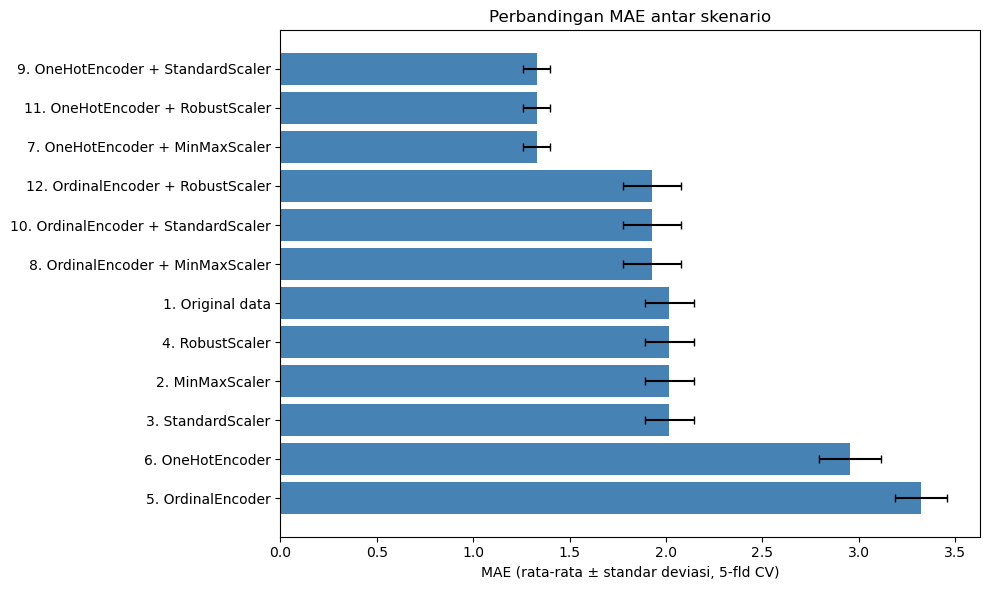

In [18]:
urut = df_hasil.sort_values('MAE rata-rata', ascending=False)

fig, ax = plt.subplots(figsize=(10,6))
ax.barh(urut['Skenario'], urut['MAE rata-rata'], xerr=urut['Standar deviasi MAE'], color='steelblue', capsize=3)
ax.set_xlabel('MAE (rata-rata ± standar deviasi, 5-fld CV)')
ax.set_title('Perbandingan MAE antar skenario')
plt.tight_layout()
plt.show()

## 8. Kesimpulan

In [19]:
terbaik = df_hasil.loc[df_hasil['MAE rata-rata'].idxmin()]
terburuk = df_hasil.loc[df_hasil['MAE rata-rata'].idxmax()]
mae_num = df_hasil[df_hasil['Skenario'].str.match(r'^[1-4]\.')]['MAE rata-rata']
mae_kat = df_hasil[df_hasil['Skenario'].str.match(r'^[56]\.')]
mae_gab = df_hasil[df_hasil["Skenario"].str.match(r'^(7|8|9|1[0-2])\.')]['MAE rata-rata']

display(Markdown(f"""
**Hasil utama**

- Skenario terbaik: **{terbaik['Skenario']}** dengan MAE {terbaik['MAE rata-rata']:.3f} (±{terbaik['Standar deviasi MAE']:.3f}).
- Skenario terburuk: **{terburuk['Skenario']}** dengan MAE {terburuk['MAE rata-rata']:.3f} (±{terburuk['Standar deviasi MAE']:.3f}).
- Skenario 1–4 (fitur numerik saja): MAE berkisar {mae_num.min():.3f} – {mae_num.max():.3f}.
- Skenario 5–6 (fitur kategorial saja): MAE berkisar {mae_kat['MAE rata-rata'].min():.3f} – {mae_kat['MAE rata-rata'].max():.3f}.
- Skenario 7–12 (semua fitur): MAE berkisar {mae_gab.min():.3f} – {mae_gab.max():.3f}.
- Sebagai pembanding skala, rata-rata `{target}` adalah {y.mean():.2f} dengan standar deviasi {y.std():.2f}.
"""))


**Hasil utama**

- Skenario terbaik: **9. OneHotEncoder + StandardScaler** dengan MAE 1.331 (±0.070).
- Skenario terburuk: **5. OrdinalEncoder** dengan MAE 3.324 (±0.134).
- Skenario 1–4 (fitur numerik saja): MAE berkisar 2.017 – 2.017.
- Skenario 5–6 (fitur kategorial saja): MAE berkisar 2.954 – 3.324.
- Skenario 7–12 (semua fitur): MAE berkisar 1.331 – 1.928.
- Sebagai pembanding skala, rata-rata `pencapaian_kecepatan` adalah 25.83 dengan standar deviasi 4.29.


# Interpretasi
1. Dari hasil pengujian, ketiga metode scaling menghasilkan MAE yang sama, yaitu 2.017. Hal ini menunjukkan bahwa scaling tidak memberikan perubahan berarti pada regresi linear yang digunakan. MinMaxScaler, StandardScaler, dan RobustScaler hanya mengubah skala fitur, sehingga hasil prediksinya tetap hampir sama.
2. Pada penggunaan fitur kategorikal saja, OneHotEncoder menghasilkan MAE 2.954, lebih kecil dibandingkan OrdinalEncoder sebesar 3.324. Hal ini kemungkinan karena OneHotEncoder tidak memberikan urutan angka pada kategori yang sebenarnya tidak memiliki tingkatan, seperti nama koridor.
3. Hasil terbaik diperoleh ketika fitur numerik dan kategorikal digunakan secara bersamaan. MAE terendah adalah 1.331, yaitu pada kombinasi OneHotEncoder dengan ketiga scaler. Hasil ini lebih baik dibandingkan penggunaan fitur numerik atau kategorikal saja.
4. Standar deviasi juga perlu diperhatikan karena menunjukkan variasi MAE pada setiap fold. Dari hasil pengujian, kombinasi OneHotEncoder dan scaler memiliki standar deviasi 0.070, lebih kecil dibandingkan beberapa skenario lainnya.
5. Berdasarkan hasil pengujian, skenario dengan OneHotEncoder dan scaler menjadi pilihan terbaik karena menghasilkan MAE paling rendah, yaitu 1.331. Ketiga scaler memberikan hasil yang sama, sehingga pemilihan scaler tidak terlalu berpengaruh pada eksperimen ini.